In [4]:

import torch.nn as nn
import torchvision
from torchvision import transforms
from torchinfo import summary
from finished_stuff.going_modular import data_getter, random_image_model_test, data_setter_loader

In [5]:
import torch
device ="cuda" if torch.cuda.is_available() else "cpu"

In [7]:
device

'cuda'

In [8]:
train_dir = "../data/food/train"
test_dir = "../data/food/test"

In [9]:
manual_transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [10]:
train_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, manual_transform, 32, 1)

In [9]:
#or make it auto
weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
auto_transform = weights.transforms()

In [10]:
train_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(train_dir, test_dir, auto_transform, 32, 1)

In [11]:
#make the model
model = torchvision.models.efficientnet_b0(weights = weights).to(device)

In [12]:
for param in model.features.parameters():
    param.requires_grad = False

In [13]:
model.classifier = nn.Sequential(
    nn.Dropout(p=0.2, inplace=True),
    nn.Linear(in_features=1280, out_features=len(classes))
).to(device)

In [14]:
summary(model,
        input_size=(32,3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [15]:
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

# HERE WE ARE GOING TO BE USING THE TENSORNOARD

In [16]:
from torch.utils.tensorboard import SummaryWriter
#using the default
writer = SummaryWriter()
writer

In [17]:

def train (model,
           train_dataloader,
           test_dataloader,
           optimizer,
           loss_fn,
           EPOCHS,
           device=device ):
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": [] }


    for epoch in tqdm(range(EPOCHS)):
        train_loss , train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device)
        test_loss , test_acc = test_step(model, test_dataloader, loss_fn, device)
        print(
          f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
        )

        # Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        #NEW: EXPERIMENT TRACKING
        writer.add_scalars(main_tag="Loss" , tag_scalar_dict={"train loss": train_loss,"test loss":test_loss}, global_step=epoch)
        writer.add_scalars(main_tag="Acc" , tag_scalar_dict={"train acc":train_acc,"test acc":test_acc}, global_step=epoch)
        writer.add_graph(model,torch.randn(32,3,224,224).to(device))#this is something that is like plt.figure in plot
    #STOP
    writer.close()

    return results




In [18]:
model_results = train(model,
                      train_dataloader,
                      test_dataloader,
                      optimizer,
                      loss_fn,
                      5,
                      device)

  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0515 | train_acc: 0.4258 | test_loss: 0.8379 | test_acc: 0.8561


 20%|██        | 1/5 [00:12<00:48, 12.04s/it]

Epoch: 2 | train_loss: 0.8292 | train_acc: 0.6719 | test_loss: 0.7841 | test_acc: 0.6411


 40%|████      | 2/5 [00:23<00:34, 11.41s/it]

Epoch: 3 | train_loss: 0.7678 | train_acc: 0.6953 | test_loss: 0.6823 | test_acc: 0.8352


 60%|██████    | 3/5 [00:34<00:22, 11.45s/it]

Epoch: 4 | train_loss: 0.6639 | train_acc: 0.7969 | test_loss: 0.6406 | test_acc: 0.8258


 80%|████████  | 4/5 [00:45<00:11, 11.20s/it]

Epoch: 5 | train_loss: 0.6436 | train_acc: 0.7656 | test_loss: 0.5778 | test_acc: 0.8674


100%|██████████| 5/5 [00:56<00:00, 11.29s/it]


In [19]:
model_results

{'train_loss': [1.0514600574970245,
  0.8292370289564133,
  0.7677812650799751,
  0.66385468095541,
  0.6435793824493885],
 'train_acc': [0.42578125, 0.671875, 0.6953125, 0.796875, 0.765625],
 'test_loss': [0.8379013538360596,
  0.784120241800944,
  0.6823155482610067,
  0.6406329472859701,
  0.5777825117111206],
 'test_acc': [0.8560606060606061,
  0.6410984848484849,
  0.8352272727272728,
  0.8257575757575758,
  0.8674242424242425]}

In [20]:
%load_ext tensorboard
%tensorboard --logdir runs

In [21]:
#MAKING A FUNCTION THAT HELPS US TO SEE WHAT IS THE PLACE THAT WE ARE GOING TO SAVE OUR TENSO BOARDS(ORGANIZE NAMING)
from torch.utils.tensorboard import SummaryWriter
from datetime import datetime
import os
def create_writer (experiment_name,
                   model_name,
                   extra):
    """FUNCTION THAT HELPS US TO SEE WHAT IS THE PLACE THAT WE ARE GOING TO SAVE OUR TENSO BOARDS(ORGANIZE NAMING)

    EX:
    runs/
└── 2025-02-03/                 (timestamp)
    └── pizza_vs_steak/         (experiment_name)
        └── efficientnet_b0/    (model_name)
            └── 5_epochs/       (extra - optional)
            """

    timestamp = datetime.now().strftime("%Y%m%d")
    if extra:
        log_dir = os.path.join("../runs", timestamp, experiment_name, model_name, extra)
    else:
        log_dir = os.path.join("../runs", timestamp, experiment_name, model_name)

    print(f"[INFO] created SummaryWriter at {log_dir}")
    return SummaryWriter(log_dir=log_dir)



In [22]:
#REMAKE THE TRAIN FUNCTION AND ADD WHAT WE MADE
from tqdm.auto import tqdm
from finished_stuff.going_modular.trainer import train_step, test_step
def train (model,
           train_dataloader,
           test_dataloader,
           optimizer,
           loss_fn,
           EPOCHS,
           device=device,
           writer=None):
    results = {"train_loss": [],
               "train_acc": [],
               "test_loss": [],
               "test_acc": [] }

    for epoch in tqdm(range(EPOCHS)):
        train_loss , train_acc = train_step(model, train_dataloader, loss_fn, optimizer, device)
        test_loss , test_acc = test_step(model, test_dataloader, loss_fn, device)
        print(
          f"Epoch: {epoch+1} | "
          f"train_loss: {train_loss:.4f} | "
          f"train_acc: {train_acc:.4f} | "
          f"test_loss: {test_loss:.4f} | "
          f"test_acc: {test_acc:.4f}"
        )

        # Update results dictionary
        results["train_loss"].append(train_loss)
        results["train_acc"].append(train_acc)
        results["test_loss"].append(test_loss)
        results["test_acc"].append(test_acc)

        #NEW: EXPERIMENT TRACKING
        if writer:
            writer.add_scalars(main_tag="Loss" , tag_scalar_dict={"train loss": train_loss,"test loss":test_loss}, global_step=epoch)
            writer.add_scalars(main_tag="Acc" , tag_scalar_dict={"train acc":train_acc,"test acc":test_acc}, global_step=epoch)
            writer.add_graph(model,torch.randn(32,3,224,224).to(device))
            #STOP
            writer.close()
        else:
            pass

    return results


# lets make some modeling experiments

In [23]:
#we already have the 10% file which is the (food) folder
data_20_percent_path = data_getter.data_getter("../data", "food_20_percent", "https://github.com/mrdbourke/pytorch-deep-learning/raw/main/data/pizza_steak_sushi_20_percent.zip")

The file there ,  downloading skipped


In [24]:
#make the directories
train_10_percent_dir = "../data/food/train"
train_20_percent_dir = "../data/food_20_percent/train"
#because we are making only one testing directory
test_dir = "../data/food/test"

train_10_percent_dir, train_20_percent_dir, test_dir

('./data/food/train', './data/food_20_percent/train', './data/food/test')

In [25]:
simple_manual_transform=transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406],
                         std=[0.229, 0.224, 0.225])
])

In [26]:
#make the Data loaders
train_10_percent_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(train_10_percent_dir, test_dir, simple_manual_transform, 32, 1)
train_20_percent_dataloader , test_dataloader , classes = data_setter_loader.data_setter_loader(
    train_20_percent_dir, test_dir,simple_manual_transform,32,1)

## make functions that make us able  to loader certain models easily --> make feature freeze (untrainable) ,etc.....

In [36]:
OUT_FEATURES = len(classes)
#model--> EffNetb0

def create_EffNetb0 (device=device):
    weights = torchvision.models.EfficientNet_B0_Weights.DEFAULT
    model = torchvision.models.efficientnet_b0(weights)
    #freeze
    for param in model.features.parameters():
        param.requires_grad = False
    #adjust classifier
    model.classifier = nn.Sequential(
      nn.Dropout(p=0.2, inplace=True),
      nn.Linear(in_features=1280, out_features=OUT_FEATURES)
    ).to(device)
    model.name = "EfficientNetB0"
    print(f"Created new {model.name} model.")
    return model

#model--> EffNetb2

def create_EffNetb2(device=device):
  # Get the weights and setup a model
  weights = torchvision.models.EfficientNet_B2_Weights.DEFAULT
  model = torchvision.models.efficientnet_b2(weights=weights).to(device)
  # Freeze
  for param in model.features.parameters():
    param.requires_grad = False
  # Change the classifier
  model.classifier = nn.Sequential(
      nn.Dropout(p=0.3, inplace=True),
      nn.Linear(in_features=1408, out_features=OUT_FEATURES)
  ).to(device)
  model.name = "EfficientNetB2"
  print(f"[INFO] Created new {model.name} model.")
  return model


In [37]:
created_model_test_effnetb0 = create_EffNetb0()
created_model_test_effnetb2 = create_EffNetb2()

Created new EfficientNetB0 model.
[INFO] Created new EfficientNetB2 model.


In [38]:
summary(model=created_model_test_effnetb0,
        input_size=(32, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1280, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

In [39]:
summary(model=created_model_test_effnetb2,
        input_size=(32, 3, 224, 224),
        verbose=0,
        col_names=["input_size", "output_size", "num_params", "trainable"],
        col_width=20,
        row_settings=["var_names"])

Layer (type (var_name))                                      Input Shape          Output Shape         Param #              Trainable
EfficientNet (EfficientNet)                                  [32, 3, 224, 224]    [32, 3]              --                   Partial
├─Sequential (features)                                      [32, 3, 224, 224]    [32, 1408, 7, 7]     --                   False
│    └─Conv2dNormActivation (0)                              [32, 3, 224, 224]    [32, 32, 112, 112]   --                   False
│    │    └─Conv2d (0)                                       [32, 3, 224, 224]    [32, 32, 112, 112]   (864)                False
│    │    └─BatchNorm2d (1)                                  [32, 32, 112, 112]   [32, 32, 112, 112]   (64)                 False
│    │    └─SiLU (2)                                         [32, 32, 112, 112]   [32, 32, 112, 112]   --                   --
│    └─Sequential (1)                                        [32, 32, 112, 112]   [32, 

## making the 8 differnt experiments

In [40]:
#epochs list
NUM_EPOCHS = [5,10]
#09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth(we need to create a new model for each new experiment
models=["EfficientNetB0","EfficientNetB2"]
#make train dataloaders dictionary
train_dataloaders={"data_10_perecent":train_10_percent_dataloader,
                   "data_20_percent":train_20_percent_dataloader}

In [42]:

experiment_number=0
for dataloader_name , train_dataloader in train_dataloaders.items():
    for epochs in NUM_EPOCHS:
        for model_name in models:
            #Print out info
            experiment_number += 1
            print(f"[INFO] Experiment number: {experiment_number}")
            print(f"[INFO] Model: {model_name}")
            print(f"[INFO] DataLoader: {dataloader_name}")
            print(f"[INFO] Number of epochs: {epochs}")
            if model_name == "EfficientNetB0":
              model=create_EffNetb0()
            else:
              model=create_EffNetb2()
            model.to(device)
            #loss and optimizer
            loss_fn = nn.CrossEntropyLoss()
            optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
            #train
            train(model,
                train_dataloader,
                test_dataloader,
                optimizer,
                loss_fn,
                epochs,
                device,
                writer=create_writer(dataloader_name,model_name,f"epochs_{epochs}"))
            #save the model
            save_filepath = f"{model_name}_{dataloader_name}_{epochs}_epochs.pth"
            model__saver.model_saver(model, "../09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth", save_filepath)
            print("-"*50 + "\n")



[INFO] Experiment number: 1
[INFO] Model: EfficientNetB0
[INFO] DataLoader: data_10_perecent
[INFO] Number of epochs: 5
Created new EfficientNetB0 model.
[INFO] created SummaryWriter at runs\20260204\data_10_perecent\EfficientNetB0\epochs_5


  0%|          | 0/5 [00:00<?, ?it/s]

Epoch: 1 | train_loss: 1.0208 | train_acc: 0.4453 | test_loss: 0.8292 | test_acc: 0.7036


 20%|██        | 1/5 [00:10<00:42, 10.61s/it]

Epoch: 2 | train_loss: 0.8994 | train_acc: 0.5898 | test_loss: 0.7666 | test_acc: 0.7131


 40%|████      | 2/5 [00:23<00:35, 11.94s/it]

... (127 outputs left out)

 90%|█████████ | 9/10 [02:10<00:14, 14.28s/it]

Epoch: 10 | train_loss: 0.3536 | train_acc: 0.9021 | test_loss: 0.3959 | test_acc: 0.9176


100%|██████████| 10/10 [02:24<00:00, 14.49s/it]

saving model to models\EfficientNetB2_data_20_percent_10_epochs.pth
--------------------------------------------------



In [43]:
%load_ext tensorboard
%tensorboard --logdir runs

The tensorboard extension is already loaded. To reload it, use:
  %reload_ext tensorboard


Reusing TensorBoard on port 6006 (pid 7072), started 0:21:35 ago. (Use '!kill 7072' to kill it.)

### here we can see the the best model is the --> b0,20%,10epochs

# lets load the model

In [45]:
best_model_path = "../../models/EfficientNetB0_data_20_percent_10_epochs.pth"
best_model = create_EffNetb0()
#load the best model
best_model.load_state_dict(torch.load(best_model_path))

Created new EfficientNetB0 model.


<All keys matched successfully>

In [52]:
#see the size
from pathlib import Path
best_model_size = Path(best_model_path).stat().st_size//(1024*1024)
print(f"the size of best model is {best_model_size}MB")

the size of best model is 15MB


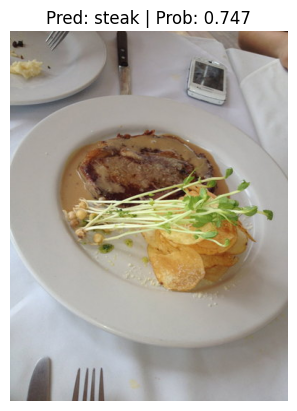

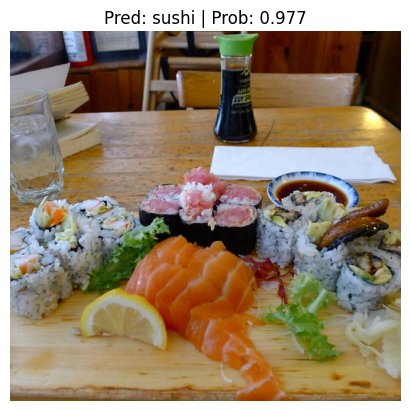

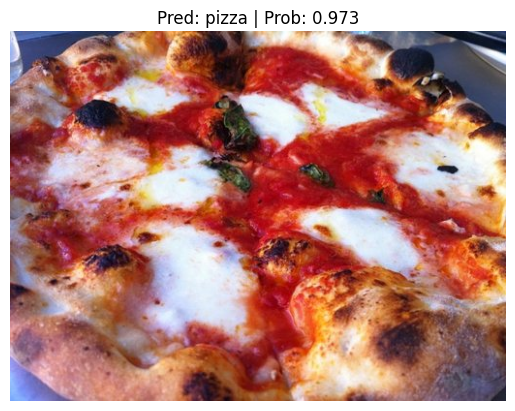

In [77]:
#make some predictions using our best 09_EFFICIENTNETB2_MODEL_TRAINED_10EPOCHES_20%PERCENT.pth
import random
num_random_images = 3
test_images_list = list(Path("../data/food_20_percent/test").glob("*/*.jpg"))
random_test_images_list = random.sample(test_images_list,num_random_images)

for random_image in random_test_images_list:
    random_image_model_test.random_image_model_test(best_model, random_image, classes, 224, device=device)

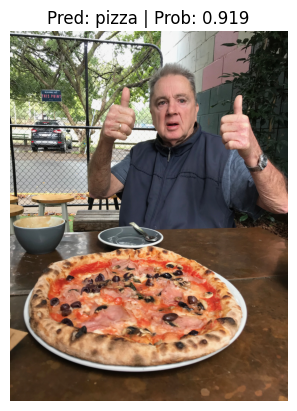

In [67]:
random_image_model_test.random_image_model_test(best_model, "../data/the trying image.jpg", classes, 224)

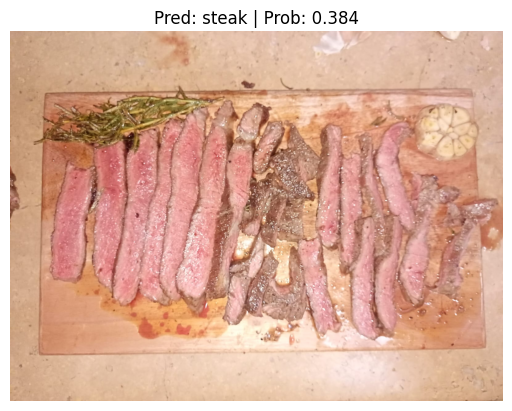

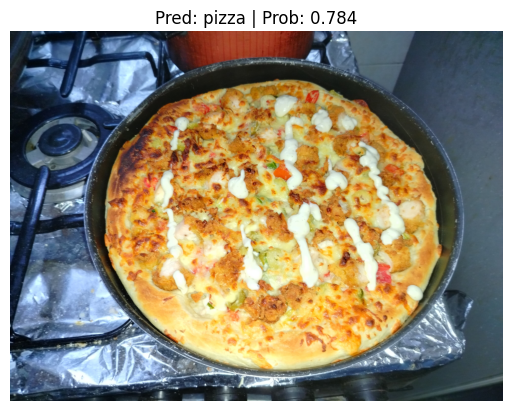

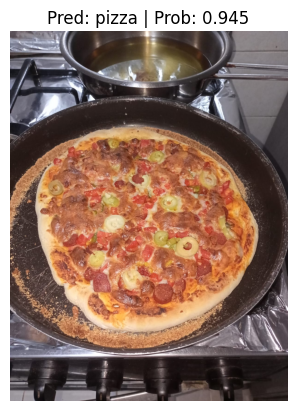

In [74]:
my_images = ["./Data/my_steak.jpg","./Data/my_pizza.jpg","./Data/my_pizza_2.jpg"]
for my_image in my_images:
    random_image_model_test.random_image_model_test(best_model, my_image, classes, 224, device=device)